# ДЗ 3.1.3. Полиномиальная регрессия, Lasso и Ridge: от чего зависит сумма заказа

БД `mobile_app`, таргет `order_total` — тот же, что в ДЗ 3.1.2. Вопрос прошлого задания: сумму заказа определяет структура покупки или вовлечённость пользователя? Здесь проверяю это на наборах с полиномами и регуляризацией.
Набор признаков модели здесь называю спецификацией. Наборы нарастают: Модель 1 — структура покупки (лучшая линейная из ДЗ 3.1.2), далее добавляются вовлечённость, полиномы, ln и 1/x с оплатой.
`unit_price` и `discount_amount` не используются: `order_total` считается через них.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet, LassoCV, RidgeCV, ElasticNetCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import train_test_split, KFold, cross_val_score
from sklearn.metrics import mean_absolute_error, mean_absolute_percentage_error, mean_squared_error, root_mean_squared_error, r2_score
from statsmodels.stats.outliers_influence import variance_inflation_factor

TARGET = "order_total"
SPLIT_SIZE, SPLIT_SEED = 0.2, 7
kf = KFold(n_splits=5, shuffle=True, random_state=SPLIT_SEED)
ALPHAS = np.logspace(-2, 5, 57)

behavioral = ["days_since_registration", "session_count_30d", "distinct_event_types_30d", "favorites_count_before"]
NUM = ["quantity"] + behavioral

def design(frame, level):
    # 1 структура покупки, 2 + вовлечённость, 3 + полиномы, 4 + ln и 1/x, оплата
    X = make_design(frame, ["quantity"], "category_name")
    if level >= 2:
        X = X.join(frame[behavioral].astype(float))
    if level >= 3:
        X["quantity_sq"] = frame["quantity"] ** 2
        X["sessions_sq"] = frame["session_count_30d"] ** 2
    if level >= 4:
        X["ln_days"] = np.log1p(frame["days_since_registration"])
        X["ln_events"] = np.log1p(frame["distinct_event_types_30d"])
        X["inv_favs"] = 1 / (1 + frame["favorites_count_before"])
        X = X.join(pd.get_dummies(frame["payment_method_name"], prefix="pay", drop_first=True).astype(float))
    return X

names = {1: "Модель 1. Структура покупки", 2: "Модель 2. + вовлечённость",
         3: "Модель 3. + полиномы", 4: "Модель 4. + ln и 1/x, оплата"}

def make_design(frame, columns, dummy_col=None):
    X = frame[columns].astype(float)
    if dummy_col:
        d = pd.get_dummies(frame[dummy_col], prefix=dummy_col, drop_first=True).astype(float)
        X = pd.concat([X, d], axis=1)
    return X

def split_train_test(X, y):
    return train_test_split(X, y, test_size=SPLIT_SIZE, random_state=SPLIT_SEED)

def visualize_prediction(y_true, y_pred, title):
    fig, ax = plt.subplots(1, 1, figsize=(5, 5))
    sns.scatterplot(x=y_true.values.ravel(), y=y_pred.ravel(), ax=ax, alpha=0.5)
    lim = [y_true.min(), y_true.max()]
    ax.plot(lim, lim, linestyle="--", color="lightblue")
    ax.set_title(title)
    ax.set_xlabel("true y")
    ax.set_ylabel("pred y")
    plt.show()

def show_metrics(y_true, y_pred):
    print("Среднее Y: ", np.mean(y_true))
    print("Ст. отклонение Y: ", np.std(y_true))
    print("MSE: ", mean_squared_error(y_true, y_pred))
    print("RMSE: ", root_mean_squared_error(y_true, y_pred))
    print("MAE: ", mean_absolute_error(y_true, y_pred))
    print("MAPE: ", mean_absolute_percentage_error(y_true, y_pred))
    print("R2: ", r2_score(y_true, y_pred))

# Открываем датасет заказов

In [2]:
df = pd.read_csv("order_value_features.csv").drop(columns="order_id")
print("Пропуски:", int(df.isna().sum().sum()), " строк:", len(df))
df.head()

Пропуски: 0  строк: 7416


,order_total,quantity,category_name,payment_method_name,days_since_registration,session_count_30d,distinct_event_types_30d,favorites_count_before
0,457.44,2,Music,mir_pay,10.0,9,10,0
1,240.32,1,Furniture,sbp,77.0,5,10,2
2,112.27,1,Music,bank_card,91.0,4,11,1
3,112.78,2,Headphones,sbp,66.0,5,10,0
4,296.59,1,Pet Supplies,bank_card,120.0,2,8,1


- `order_total` — сумма заказа (таргет, вещественная переменная);
- `quantity` — число единиц товара;
- `category_name`, `payment_method_name` — категория и способ оплаты;
- `days_since_registration`, `session_count_30d`, `distinct_event_types_30d`, `favorites_count_before` — активность до заказа.

# 1. Что предсказываем и чем

count    7416.000000
mean      279.183815
std       458.641775
min         2.640000
25%        69.087500
50%       146.430000
75%       305.100000
max      7266.700000
Name: order_total, dtype: float64


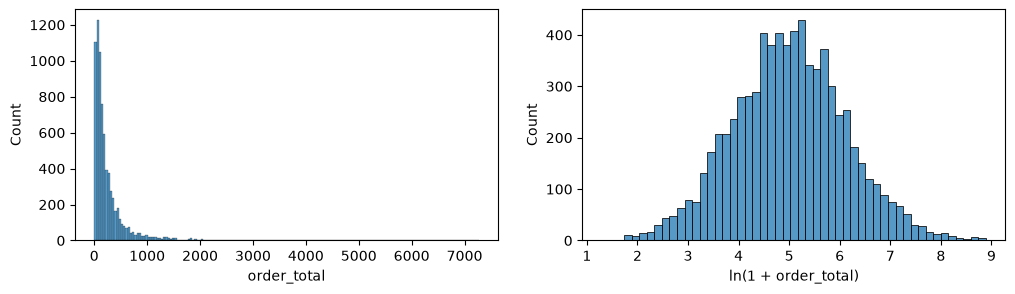

In [3]:
print(df[TARGET].describe())
fig, ax = plt.subplots(1, 2, figsize=(12, 3))
sns.histplot(data=df, x=TARGET, ax=ax[0])
sns.histplot(x=np.log1p(df[TARGET]), ax=ax[1])
ax[1].set_xlabel("ln(1 + order_total)")
plt.show()

In [4]:
def iqr_share(s):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return round(((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).mean() * 100, 2)

pd.DataFrame({"IQR, %": {col: iqr_share(df[col]) for col in [TARGET] + NUM},
              "skew": {col: round(df[col].skew(), 3) for col in [TARGET] + NUM}})

,"IQR, %",skew
order_total,8.86,6.157
quantity,2.13,1.776
days_since_registration,0.59,0.929
session_count_30d,6.43,1.947
distinct_event_types_30d,26.31,-1.937
favorites_count_before,0.59,1.218


Таргет сильно скошен вправо (skew ≈ 6). Это реальные покупки, поэтому выбросы не удаляю. Логарифм таргета не использую: задание его не требует, а для сравнения наборов признаков удобнее одна шкала.

# 2. Диаграммы рассеяния: сумма заказа против признаков

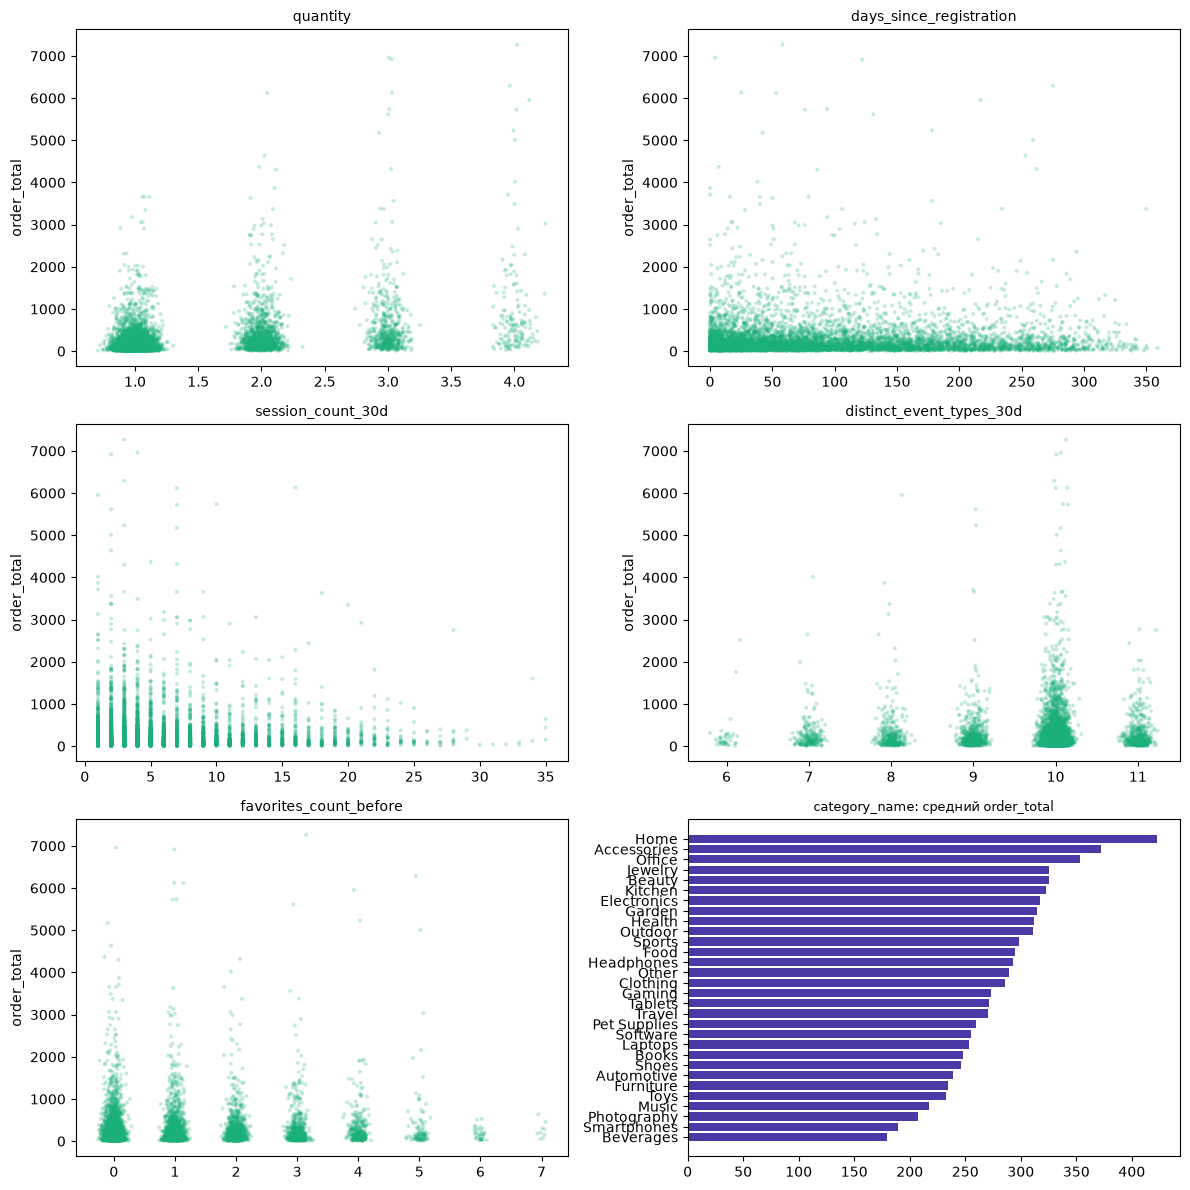

In [5]:
fig, axes = plt.subplots(3, 2, figsize=(12, 12))
axes = axes.ravel()
rng = np.random.default_rng(SPLIT_SEED)
for ax, col in zip(axes, NUM):
    jitter = rng.normal(0, 0.08, size=len(df)) if df[col].nunique() < 20 else 0
    ax.scatter(df[col] + jitter, df[TARGET], s=8, alpha=0.25, color="#1baf7a", edgecolor="none")
    ax.set_title(col, fontsize=10)
    ax.set_ylabel(TARGET)

cat_means = df.groupby("category_name")[TARGET].mean().sort_values()
axes[5].barh(cat_means.index, cat_means.values, color="#4a3aa7")
axes[5].set_title("category_name: средний order_total", fontsize=9)
plt.tight_layout()
plt.show()

**Форма связи:**
- `quantity`: с ростом количества поднимается верхняя часть облака (крупные заказы чаще при 3–4 единицах), но основная масса заказов низкая. Связь слабая и держится на хвосте.
- признаки вовлечённости (дни, сессии, типы событий, избранное): облака плотные, без выраженного наклона. У `session_count_30d` верхняя граница убывает, но в центре облака связи не видно.
- `category_name`: средний чек различается почти вдвое (от ≈180 в `Beverages` до ≈420 в `Home`).

# 3. Наборы признаков и коллинеарность

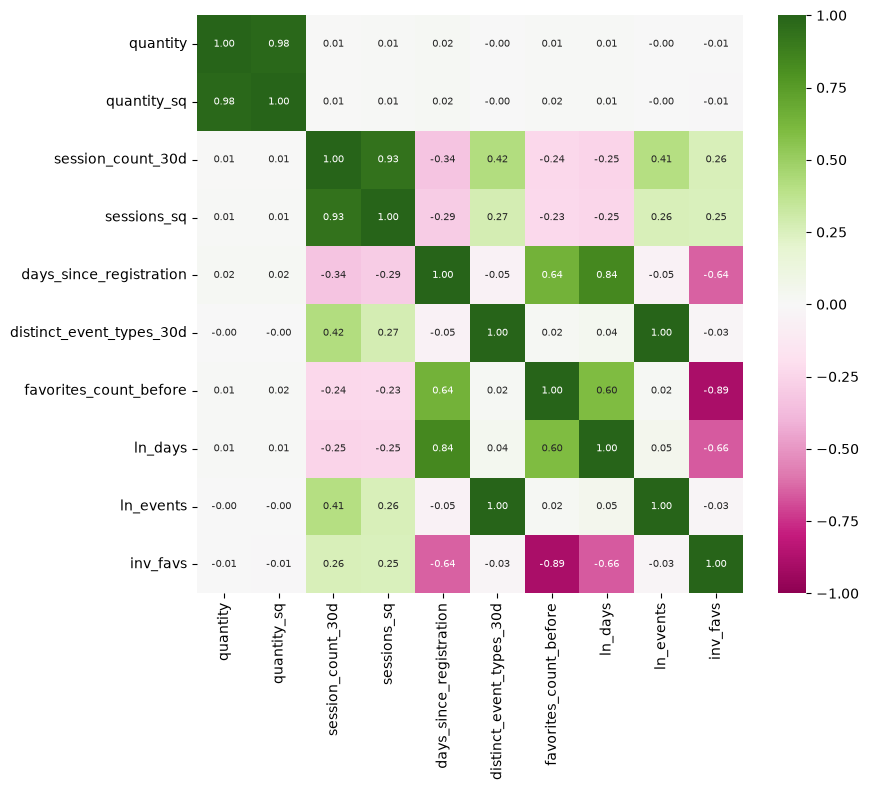

Пары с |r| >= 0.8:
('quantity', 'quantity_sq', np.float64(0.98))
('session_count_30d', 'sessions_sq', np.float64(0.933))
('days_since_registration', 'ln_days', np.float64(0.838))
('distinct_event_types_30d', 'ln_events', np.float64(0.997))
('favorites_count_before', 'inv_favs', np.float64(-0.895))


In [6]:
full = design(df, 4)
num_full = ["quantity", "quantity_sq", "session_count_30d", "sessions_sq", "days_since_registration",
            "distinct_event_types_30d", "favorites_count_before", "ln_days", "ln_events", "inv_favs"]
corr = full[num_full].corr()
fig, ax = plt.subplots(figsize=(9, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="PiYG", vmin=-1, vmax=1, annot_kws={"size": 7}, ax=ax)
plt.tight_layout()
plt.show()

pairs = [(a, b, round(corr.loc[a, b], 3)) for i, a in enumerate(corr.columns) for b in corr.columns[i + 1:]
         if abs(corr.loc[a, b]) >= 0.8]
print("Пары с |r| >= 0.8:")
for p in pairs:
    print(p)

In [7]:
vif = pd.DataFrame({"feature": num_full,
                    "VIF": [variance_inflation_factor(full[num_full].values, i) for i in range(len(num_full))]})
vif.sort_values("VIF", ascending=False).reset_index(drop=True)

,feature,VIF
0,distinct_event_types_30d,203.370872
1,ln_events,200.760824
2,quantity_sq,24.752143
3,quantity,24.751017
4,session_count_30d,10.607913
5,sessions_sq,9.075886
6,inv_favs,5.787187
7,favorites_count_before,5.391705
8,days_since_registration,4.083019
9,ln_days,3.900896


**Наборы признаков (нарастающим итогом):**
1. **Модель 1 — структура покупки:** `quantity` и дамми категории;
2. **Модель 2 — + вовлечённость:** четыре признака активности до заказа;
3. **Модель 3 — + полиномы:** `quantity²`, `sessions²`;
4. **Модель 4 — + ln и 1/x, оплата:** ln(1 + дни), ln(1 + типы событий), 1/(1 + избранное), дамми способа оплаты.

**Вывод по мультиколлинеарности:** при полиномах и преобразованиях появляются пары с |r| ≈ 0.9–1.0 (`quantity` и `quantity²`, `типы событий` и их ln). VIF у типов событий и их ln около 200, у `quantity` и `quantity²` около 25. OLS на полном наборе даёт нестабильные коэффициенты, поэтому сравниваю OLS как эталон и Lasso/Ridge.

# 4. Делим данные на train и test

In [8]:
X_tr_full, X_te_full, y_train, y_test = train_test_split(design(df, 4), df[TARGET], test_size=SPLIT_SIZE, random_state=SPLIT_SEED)
print("Train:", X_tr_full.shape, " Test:", X_te_full.shape)

Train: (5932, 46)  Test: (1484, 46)


# 5. Приводим признаки к одному масштабу

Признаки масштабируем: иначе сила штрафа Lasso и Ridge зависит от единиц (количество, дни, сессии, дамми). Масштаб берётся по обучающей выборке и применяется к тесту. В пайплайне масштабирование стоит внутри CV, поэтому тест не участвует в настройке.

In [9]:
scaler = StandardScaler().fit(X_tr_full)
X_tr_sc = pd.DataFrame(scaler.transform(X_tr_full), columns=X_tr_full.columns, index=X_tr_full.index)
X_te_sc = pd.DataFrame(scaler.transform(X_te_full), columns=X_te_full.columns, index=X_te_full.index)
pd.DataFrame({"среднее train": X_tr_sc.mean(), "ст. откл. train": X_tr_sc.std(),
              "среднее test": X_te_sc.mean(), "ст. откл. test": X_te_sc.std()}).round(3).head(10)

,среднее train,ст. откл. train,среднее test,ст. откл. test
quantity,-0.0,1.0,-0.026,0.976
category_name_Automotive,0.0,1.0,-0.014,0.964
category_name_Beauty,-0.0,1.0,-0.017,0.954
category_name_Beverages,-0.0,1.0,-0.067,0.820
category_name_Books,0.0,1.0,-0.009,0.973
category_name_Clothing,0.0,1.0,0.026,1.076
category_name_Electronics,-0.0,1.0,0.018,1.050
category_name_Food,0.0,1.0,0.010,1.029
category_name_Furniture,-0.0,1.0,0.007,1.016
category_name_Gaming,-0.0,1.0,-0.005,0.989


# 6. Подбор Lasso и Ridge для каждого набора

Для каждого набора признаков подбираю Lasso и Ridge. `alpha` подбирается `GridSearchCV` по 5-fold CV на обучающей выборке. Тест используется только для оценки.

In [10]:
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV

results, fitted = [], {}
for lvl, name in names.items():
    X_tr, X_te, y_tr, y_te = split_train_test(design(df, lvl), df[TARGET])
    for kind, est in [("Lasso", Lasso(max_iter=100000)), ("Ridge", Ridge())]:
        search = GridSearchCV(Pipeline([("sc", StandardScaler()), ("m", est)]), {"m__alpha": ALPHAS}, cv=kf, scoring="r2")
        search.fit(X_tr, y_tr)
        final = search.best_estimator_
        pred = final.predict(X_te)
        results.append({"спецификация": name, "метод": kind, "признаков": X_tr.shape[1],
                        "alpha": round(search.best_params_["m__alpha"], 4),
                        "ненулевых коэф.": int(np.sum(np.abs(final["m"].coef_) > 1e-10)),
                        "CV R2 (train)": round(search.best_score_, 4),
                        "R2 (test)": round(r2_score(y_te, pred), 4),
                        "RMSE (test)": round(root_mean_squared_error(y_te, pred), 3),
                        "MAE (test)": round(mean_absolute_error(y_te, pred), 3)})
        fitted[(lvl, kind)] = (final, X_tr.columns.tolist(), pred, y_te)

pd.DataFrame(results)

,спецификация,метод,признаков,alpha,ненулевых коэф.,CV R2 (train),R2 (test),RMSE (test),MAE (test)
0,Модель 1. Структура покупки,Lasso,30,5.6234,15,0.1240,0.0902,423.111,223.439
1,Модель 1. Структура покупки,Ridge,30,56.2341,30,0.1227,0.0878,423.663,226.035
2,Модель 2. + вовлечённость,Lasso,34,5.6234,16,0.1241,0.0891,423.360,223.823
3,Модель 2. + вовлечённость,Ridge,34,74.9894,34,0.1224,0.0856,424.179,226.824
4,Модель 3. + полиномы,Lasso,36,5.6234,18,0.1261,0.0765,426.282,224.862
5,Модель 3. + полиномы,Ridge,36,562.3413,36,0.1250,0.0815,425.119,225.858
6,"Модель 4. + ln и 1/x, оплата",Lasso,46,5.6234,22,0.1261,0.0765,426.276,224.893
7,"Модель 4. + ln и 1/x, оплата",Ridge,46,749.8942,46,0.1242,0.0816,425.102,225.918


**Что видно по спецификациям:**
- Lasso и Ridge дают тестовый R² 0.077–0.090. Lasso лучше на Моделях 1–2 (0.089–0.090), на Моделях 3–4 — 0.077.
- Lasso оставляет 15–22 ненулевых коэффициента, в основном категории и `quantity`. В Модели 2 он обнулил три из четырёх признаков вовлечённости.
- Ridge ничего не обнуляет. Alpha Lasso во всех спецификациях одинаковая — 5.62, причину не разбирал.

# 7. Итоговое сравнение и отбор модели

По CV R² на train выбираю между Lasso и Ridge; OLS — контрольная линия без штрафа.

In [11]:
rows = []
for lvl, name in names.items():
    X_tr, X_te, y_tr, y_te = split_train_test(design(df, lvl), df[TARGET])
    ols = Pipeline([("sc", StandardScaler()), ("m", LinearRegression())])
    rows.append({"спецификация": name, "метод": "OLS (эталон)",
                 "CV R2 (train)": round(cross_val_score(ols, X_tr, y_tr, cv=kf, scoring="r2").mean(), 4),
                 "R2 (test)": round(r2_score(y_te, ols.fit(X_tr, y_tr).predict(X_te)), 4)})
    for kind in ["Lasso", "Ridge"]:
        final, cols, pred, _ = fitted[(lvl, kind)]
        rows.append({"спецификация": name, "метод": kind,
                     "CV R2 (train)": round(next(r for r in results if r["спецификация"] == name and r["метод"] == kind)["CV R2 (train)"], 4),
                     "R2 (test)": round(r2_score(y_te, pred), 4)})
cmp_df = pd.DataFrame(rows)
cmp_df

,спецификация,метод,CV R2 (train),R2 (test)
0,Модель 1. Структура покупки,OLS (эталон),0.1226,0.0865
1,Модель 1. Структура покупки,Lasso,0.1240,0.0902
2,Модель 1. Структура покупки,Ridge,0.1227,0.0878
3,Модель 2. + вовлечённость,OLS (эталон),0.1223,0.0838
4,Модель 2. + вовлечённость,Lasso,0.1241,0.0891
5,Модель 2. + вовлечённость,Ridge,0.1224,0.0856
6,Модель 3. + полиномы,OLS (эталон),0.1237,0.0701
7,Модель 3. + полиномы,Lasso,0.1261,0.0765
8,Модель 3. + полиномы,Ridge,0.1250,0.0815
9,"Модель 4. + ln и 1/x, оплата",OLS (эталон),0.1219,0.0685


Лучшая по CV R2 (train): Модель 3. + полиномы / Lasso
Её тестовый R2: 0.0765


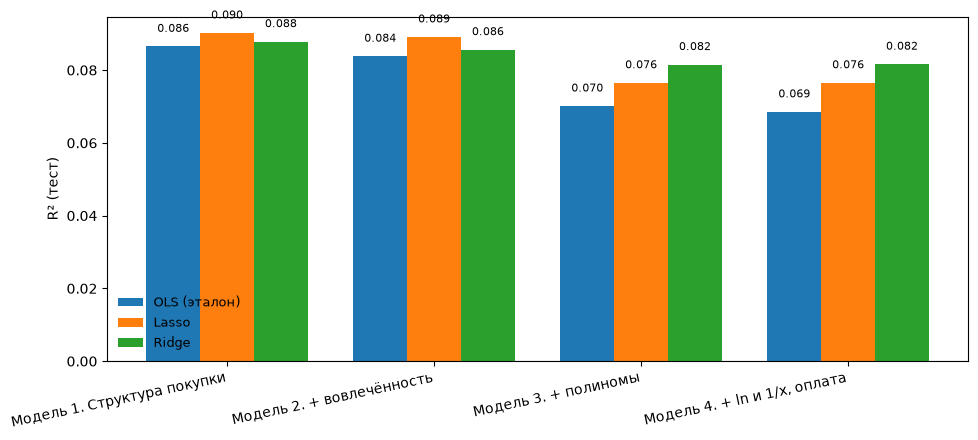

In [12]:
sel = cmp_df[cmp_df["метод"] != "OLS (эталон)"]
best = sel.loc[sel["CV R2 (train)"].idxmax()]
print("Лучшая по CV R2 (train):", best["спецификация"], "/", best["метод"])
print("Её тестовый R2:", best["R2 (test)"])

fig, ax = plt.subplots(figsize=(10, 4.5))
piv = cmp_df.pivot(index="спецификация", columns="метод", values="R2 (test)")[["OLS (эталон)", "Lasso", "Ridge"]]
x = np.arange(len(piv.index))
w = 0.26
for i, col in enumerate(piv.columns):
    ax.bar(x + (i - 1) * w, piv[col], width=w, label=col)
    for xi, v in zip(x + (i - 1) * w, piv[col]):
        ax.text(xi, v + 0.004 if v >= 0 else v - 0.012, f"{v:.3f}", ha="center", fontsize=8)
ax.set_xticks(x)
ax.set_xticklabels(piv.index, rotation=12, ha="right")
ax.axhline(0, color="grey", lw=0.8)
ax.set_ylabel("R² (тест)")
ax.legend(frameon=False, fontsize=9)
plt.tight_layout()
plt.show()

**Выбор.** По CV среди Lasso и Ridge лучшая — **Модель 3 + Lasso** (CV 0.1261, тест R² 0.0765). По тесту лучше **Модель 1 + Lasso** (тест 0.0902, CV 0.1240). Разница по CV — 0.002, в пределах шума, поэтому CV не даёт однозначного ответа. Вывод от выбора не меняется: полиномы на тесте не помогают, простая структура покупки не уступает полной модели.

# 8. Что говорят коэффициенты лучшей модели

In [13]:
best_key = next(k for k in fitted if names[k[0]] == best["спецификация"] and k[1] == best["метод"])
best_est, best_cols, best_pred, best_y = fitted[best_key]
std_coef = best_est["m"].coef_
scale = best_est["sc"].scale_
interp = pd.DataFrame({"коэф. (стандартизованные)": std_coef,
                       "коэф. (исходная шкала, ₽)": std_coef / scale}, index=best_cols)
print("Лучшая модель:", best["спецификация"], "/", best["метод"], " alpha =", best_est.named_steps["m"].alpha)
interp.reindex(interp["коэф. (стандартизованные)"].abs().sort_values(ascending=False).index).round(3)

Лучшая модель: Модель 3. + полиномы / Lasso  alpha = 5.623413251903491


,коэф. (стандартизованные),"коэф. (исходная шкала, ₽)"
quantity_sq,151.221,50.007
category_name_Home,18.547,113.794
category_name_Smartphones,-13.499,-70.816
category_name_Beverages,-11.359,-58.964
category_name_Office,10.630,54.275
category_name_Photography,-9.318,-51.502
category_name_Furniture,-8.380,-42.873
quantity,7.765,10.739
favorites_count_before,7.512,5.732
category_name_Outdoor,7.496,43.123


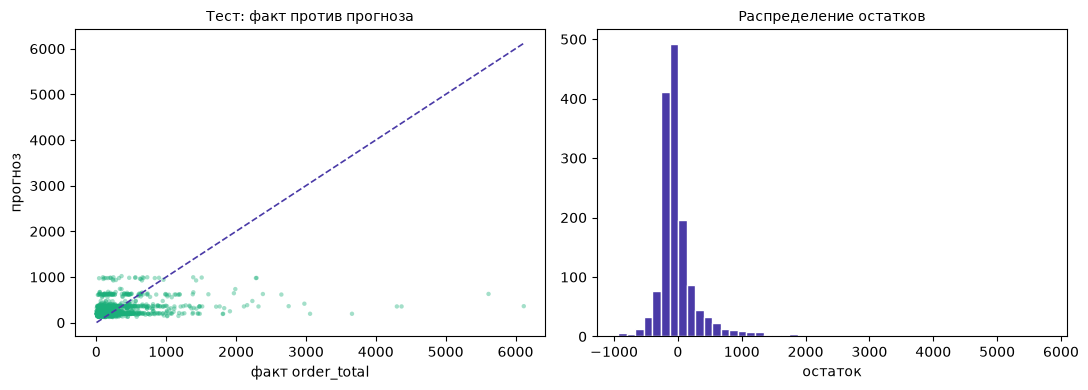

Средний остаток: 2.773


In [14]:
resid = best_y.values - best_pred
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].scatter(best_y, best_pred, s=10, alpha=0.4, color="#1baf7a", edgecolor="none")
lims = [best_y.min(), best_y.max()]
axes[0].plot(lims, lims, color="#4a3aa7", lw=1.2, ls="--")
axes[0].set_xlabel("факт order_total")
axes[0].set_ylabel("прогноз")
axes[0].set_title("Тест: факт против прогноза", fontsize=10)
axes[1].hist(resid, bins=50, color="#4a3aa7", edgecolor="white")
axes[1].set_title("Распределение остатков", fontsize=10)
axes[1].set_xlabel("остаток")
plt.tight_layout()
plt.show()
print("Средний остаток:", round(resid.mean(), 3))

**Что означают коэффициенты (Модель 3 + Lasso, исходная шкала, ₽):**
- `quantity` ≈ +11 ₽ за единицу и `quantity²` ≈ +50 ₽. Вместе дают нелинейный рост суммы с количеством; по отдельности интерпретировать нельзя;
- категории относительно базовой `Accessories`: `Home` ≈ +114 ₽, `Smartphones` ≈ −71 ₽, `Beverages` ≈ −59 ₽;
- вовлечённость: `favorites_count_before` ≈ +6 ₽ за единицу, остальные признаки вовлечённости обнулены.

**Остатки:** средний остаток ≈ +2.8 ₽ при среднем чеке 280 — систематического смещения почти нет.

# 9. Итоги и ограничения

**Качество.** Тестовый R² всех 12 комбинаций (Модели 1–4 × OLS/Lasso/Ridge) лежит в диапазоне 0.069–0.090. Модель объясняет меньше 10% разброса суммы заказа.

**Спецификации.** Полиномы и преобразования на тесте качество не повышают: OLS Модели 3 даёт 0.070 против 0.087 у Модели 1. Lasso и Ridge частично выправляют это (Lasso 0.077, Ridge 0.082 на Модели 3), но до простой модели не доходят.

**Выбор.** По CV лучшая — Модель 3 + Lasso, по тесту — Модель 1 + Lasso (тест 0.090). Разница по CV в пределах шума. Практический вывод: сумму заказа определяет структура покупки (`quantity`, категория), вовлечённость почти не добавляет.

**Итог.** Для точного прогноза нужна цена товара или другие данные: без неё R² не выходит за 0.09.

**Ограничения:** одно разбиение train/test (`random_state=7`); alpha Lasso одинаковая (5.62) во всех спецификациях, причину не разбирал; alpha Ridge для Модели 4 ≈ 750 внутри сетки до 1e5.